In [88]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
from pandas.core import sample

torch.manual_seed(42)

In [89]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch, 'mps') and torch.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

In [90]:
device

device(type='cpu')

In [91]:
sample_tensor = torch.tensor([[1.0,2.0],[3.0,4.0]])
print("Before moving: ", sample_tensor.device)
sample_tensor = sample_tensor.to(device)
print("After moving: ", sample_tensor.device)

Before moving:  cpu
After moving:  cpu


In [92]:
# transforms.ToTensor() + transforms.Normalize()
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

In [93]:
train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform,
)
test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform,
)

In [94]:
len(train_dataset), len(test_dataset)

(60000, 10000)

In [95]:
batch_size = 64
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
)
test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False,
)

In [96]:
len(train_loader), len(test_loader)

(938, 157)

In [97]:
image, label = train_dataset[0]

In [98]:
image.shape

torch.Size([1, 28, 28])

In [99]:
label

5

In [100]:
image.dtype

torch.float32

In [101]:
image.device

device(type='cpu')

In [102]:
def show_mnist_image(image_tensor, label):
     image = image_tensor.squeeze()
     image = image * 0.3081 + 0.1307

     plt.imshow(image, cmap='gray')
     plt.title(f"Label: {label}")
     plt.axis("off")
     plt.show()

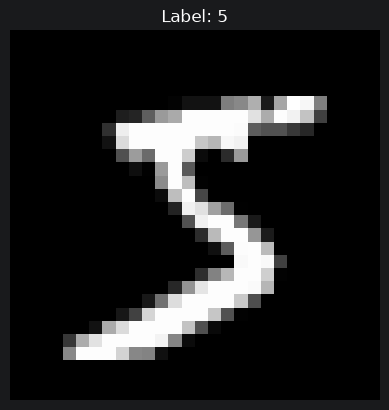

In [103]:
show_mnist_image(image, label)

In [104]:
images, labels = next(iter(train_loader))

In [105]:
images.shape, labels.shape

(torch.Size([64, 1, 28, 28]), torch.Size([64]))

In [106]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.layers(x)
        return x

In [107]:
model = MNISTClassifier().to(device)
print(model)
print("\nModel Device: ", next(model.parameters()).device)

MNISTClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)

Model Device:  cpu


In [108]:
images = images.to(device)
labels = labels.to(device)

logits = model(images)
logits.shape, logits.shape

(torch.Size([64, 10]), torch.Size([64, 10]))

In [109]:
image.shape, logits.shape

(torch.Size([1, 28, 28]), torch.Size([64, 10]))

In [110]:
logits[0]

tensor([ 0.1040,  0.3707,  0.0853, -0.0407, -0.0527, -0.0191,  0.1609, -0.1665,
         0.1527, -0.1726], grad_fn=<SelectBackward0>)

In [111]:
predicted_classes = logits.argmax(dim=1)

In [112]:
predicted_classes[:10]

tensor([1, 8, 8, 8, 8, 8, 8, 8, 8, 8])

In [113]:
labels[:10]

tensor([1, 2, 8, 5, 2, 6, 9, 9, 9, 4])

In [114]:
loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [115]:
loss_function, optimizer

(CrossEntropyLoss(),
 Adam (
 Parameter Group 0
     amsgrad: False
     betas: (0.9, 0.999)
     capturable: False
     decoupled_weight_decay: False
     differentiable: False
     eps: 1e-08
     foreach: None
     fused: None
     lr: 0.01
     maximize: False
     weight_decay: 0
 ))

In [116]:
num_epoches = 1

for epoch in range(num_epoches):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        data, targets = data.to(device), target.to(device)

        optimizer.zero_grad()

        outputs = model(data)
        loss = loss_function(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predicted = outputs.argmax(dim=1)
        total += targets.size(0)
        correct += (predicted == targets).sum().item()

        if (batch_idx + 1) % 200 == 0:
            avg_loss = running_loss / (batch_idx + 1)
            accuracy = 100 * correct / total
            print(f"Epoch {epoch+1} | Batch {batch_idx+1} | Loss: {avg_loss:.4f} | Train Acc: {accuracy:.2f}%")
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total
    print(f"\nEpoch {epoch+1} complete | Losss: {epoch_loss:.4f} | Train Acc: {epoch_accuracy:.2f}%\n")

Epoch 1 | Batch 200 | Loss: 0.4011 | Train Acc: 87.63%
Epoch 1 | Batch 400 | Loss: 0.3352 | Train Acc: 89.91%
Epoch 1 | Batch 600 | Loss: 0.3021 | Train Acc: 91.02%
Epoch 1 | Batch 800 | Loss: 0.2890 | Train Acc: 91.52%

Epoch 1 complete | Losss: 0.2838 | Train Acc: 91.76%



In [117]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for data, targets in test_loader:
        data = data.to(device)
        targets = targets.to(device)

        outputs = model(data)
        predicted = outputs.argmax(dim=1)

        total += targets.size(0)
        correct += (predicted == targets).sum().item()

    test_accuracy = 100 * correct / total
    print(f"\nTest Accuracy: {test_accuracy:.2f}%")


Test Accuracy: 93.26%


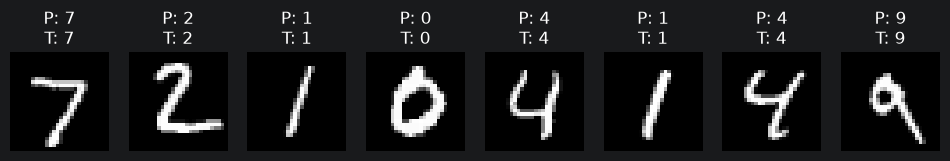

In [118]:
model.eval()

test_image, test_labels = next(iter(test_loader))
test_images_device = test_image.to(device)

with torch.no_grad():
    test_outputs = model(test_images_device)
    test_predictions = test_outputs.argmax(dim=1).cpu()
plt.figure(figsize=(12, 3))

for i in range(8):
    image = test_image[i].squeeze()
    image = image * 0.3081 + 0.1307 # undo normalization for display

    plt.subplot(1,8,i+1)
    plt.imshow(image, cmap='gray')
    plt.title(f"P: {test_predictions[i].item()}\nT: {test_labels[i].item()}")
    plt.axis("off")

plt.show()